In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
df = pd.read_csv('world_happiness.csv')


In [4]:
df.head()


,Country,Year,Happiness_Score,GDP_per_Capita,Social_Support,Healthy_Life_Expectancy,Freedom,Generosity,Corruption_Perception
0,China,2022,4.39,44984.68,0.53,71.11,0.41,-0.05,0.83
1,UK,2015,5.49,30814.59,0.93,63.14,0.89,0.04,0.84
2,Brazil,2009,4.65,39214.84,0.03,62.36,0.01,0.16,0.59
3,France,2019,5.20,30655.75,0.77,78.94,0.98,0.25,0.63
4,China,2022,7.28,30016.87,0.05,50.33,0.62,0.18,0.92


In [5]:
df.shape


(150, 9)

In [6]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Country                  150 non-null    str    
 1   Year                     150 non-null    int64  
 2   Happiness_Score          150 non-null    float64
 3   GDP_per_Capita           150 non-null    float64
 4   Social_Support           150 non-null    float64
 5   Healthy_Life_Expectancy  150 non-null    float64
 6   Freedom                  150 non-null    float64
 7   Generosity               150 non-null    float64
 8   Corruption_Perception    150 non-null    float64
dtypes: float64(7), int64(1), str(1)
memory usage: 10.7 KB


In [7]:
df.isnull().sum()


Country                    0
Year                       0
Happiness_Score            0
GDP_per_Capita             0
Social_Support             0
Healthy_Life_Expectancy    0
Freedom                    0
Generosity                 0
Corruption_Perception      0
dtype: int64

In [8]:
df.duplicated().sum()


np.int64(0)

In [9]:
df = df.drop_duplicates()

numeric_columns = df.select_dtypes(include=np.number).columns
df[numeric_columns] = df[numeric_columns].fillna(df[numeric_columns].median())

df['Country'] = df['Country'].fillna('Unknown')

df.isnull().sum()


Country                    0
Year                       0
Happiness_Score            0
GDP_per_Capita             0
Social_Support             0
Healthy_Life_Expectancy    0
Freedom                    0
Generosity                 0
Corruption_Perception      0
dtype: int64

In [10]:
df.describe()


,Year,Happiness_Score,GDP_per_Capita,Social_Support,Healthy_Life_Expectancy,Freedom,Generosity,Corruption_Perception
count,150.000000,150.000000,150.000000,150.000000,150.000000,150.000000,150.000000,150.000000
mean,2014.573333,5.554200,30501.338067,0.506133,68.041867,0.552000,0.153133,0.497533
std,5.758387,1.532223,16186.745941,0.300681,9.692135,0.289684,0.200490,0.295139
min,2005.000000,3.050000,1531.330000,0.010000,50.040000,0.010000,-0.200000,0.000000
25%,2009.250000,4.182500,17568.577500,0.245000,61.107500,0.302500,-0.010000,0.220000
50%,2015.000000,5.550000,30727.080000,0.480000,67.990000,0.605000,0.150000,0.520000
75%,2019.750000,6.990000,44591.077500,0.770000,76.152500,0.790000,0.310000,0.760000
max,2024.000000,7.990000,59632.610000,1.000000,84.670000,1.000000,0.500000,1.000000


In [11]:
correlation_columns = [
    'Happiness_Score',
    'GDP_per_Capita',
    'Social_Support',
    'Healthy_Life_Expectancy',
    'Freedom',
    'Generosity',
    'Corruption_Perception'
]

correlation_matrix = df[correlation_columns].corr()
correlation_matrix


,Happiness_Score,GDP_per_Capita,Social_Support,Healthy_Life_Expectancy,Freedom,Generosity,Corruption_Perception
Happiness_Score,1.000000,0.015076,0.008496,0.102816,-0.102875,0.177320,-0.001569
GDP_per_Capita,0.015076,1.000000,0.011964,-0.080316,-0.065965,-0.058036,-0.033468
Social_Support,0.008496,0.011964,1.000000,-0.097682,-0.072748,-0.075202,0.096400
Healthy_Life_Expectancy,0.102816,-0.080316,-0.097682,1.000000,0.015972,-0.044159,-0.122438
Freedom,-0.102875,-0.065965,-0.072748,0.015972,1.000000,0.043075,-0.107328
Generosity,0.177320,-0.058036,-0.075202,-0.044159,0.043075,1.000000,0.050978
Corruption_Perception,-0.001569,-0.033468,0.096400,-0.122438,-0.107328,0.050978,1.000000


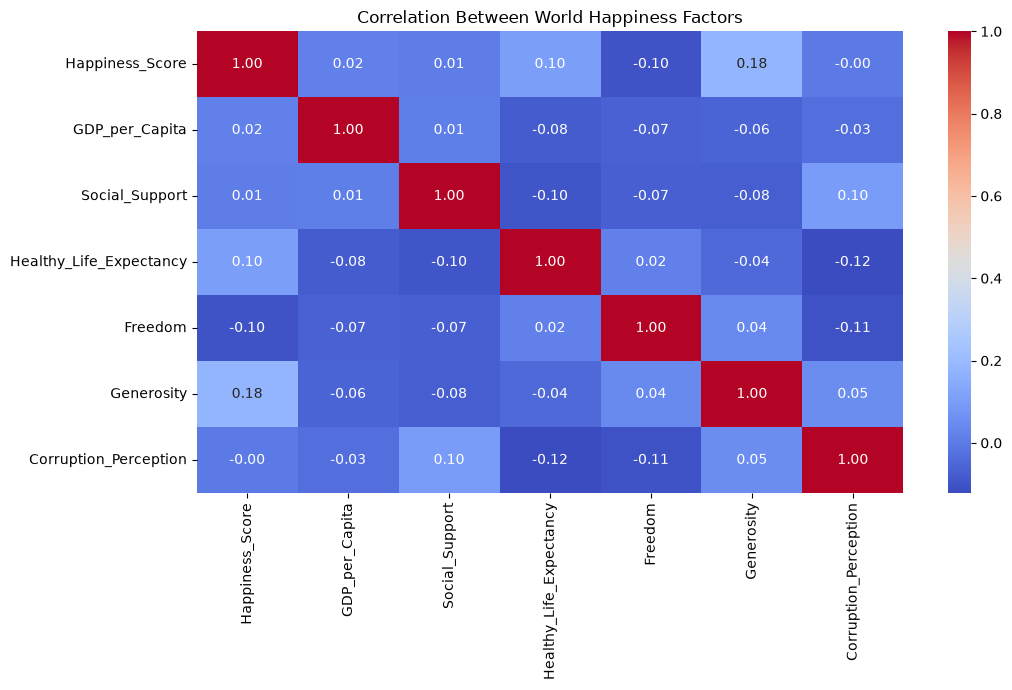

In [12]:
plt.figure(figsize=(11, 7))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Between World Happiness Factors')
plt.tight_layout()
plt.show()


In [13]:
top_countries = (
    df.groupby('Country')['Happiness_Score']
      .mean()
      .sort_values(ascending=False)
      .head(5)
)
top_countries


Country
USA             6.163077
Australia       6.024444
UK              5.607857
South Africa    5.585625
Germany         5.576667
Name: Happiness_Score, dtype: float64

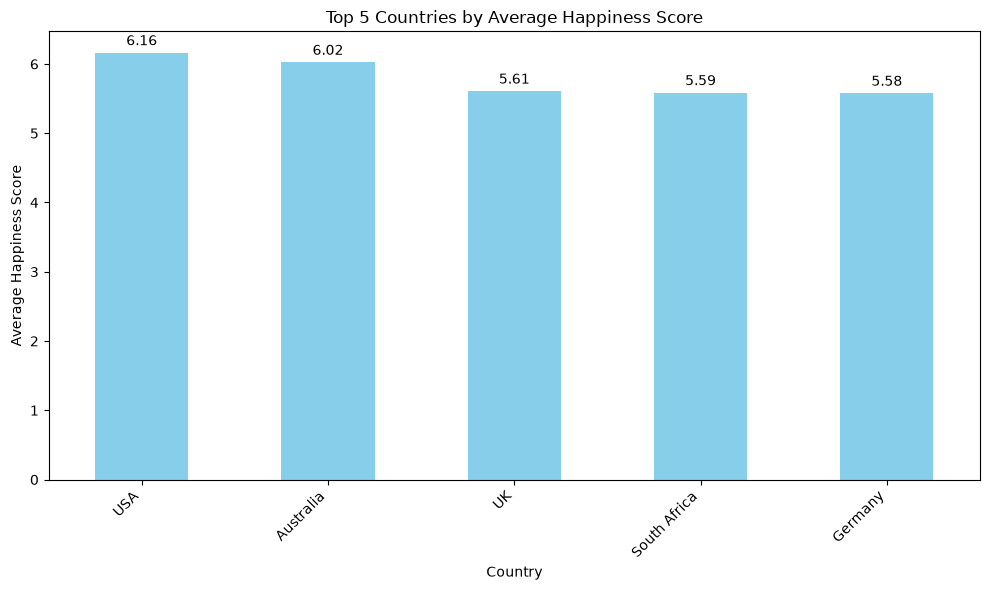

In [14]:
ax = top_countries.plot(kind='bar', figsize=(10, 6), color='skyblue')
plt.bar_label(ax.containers[0], fmt='%.2f', padding=3)

plt.title('Top 5 Countries by Average Happiness Score')
plt.xlabel('Country')
plt.ylabel('Average Happiness Score')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


In [15]:
yearly_happiness = df.groupby('Year')['Happiness_Score'].mean().sort_index()
yearly_happiness


Year
2005    6.060909
2006    6.942000
2007    5.868750
2008    5.526667
2009    5.898750
2010    5.008000
2011    4.135556
2012    4.453333
2013    4.906250
2014    5.079000
2015    6.161250
2016    6.712500
2017    6.051111
2018    5.523333
2019    5.140833
2020    5.253750
2021    5.840000
2022    6.963333
2023    5.060000
2024    4.643333
Name: Happiness_Score, dtype: float64

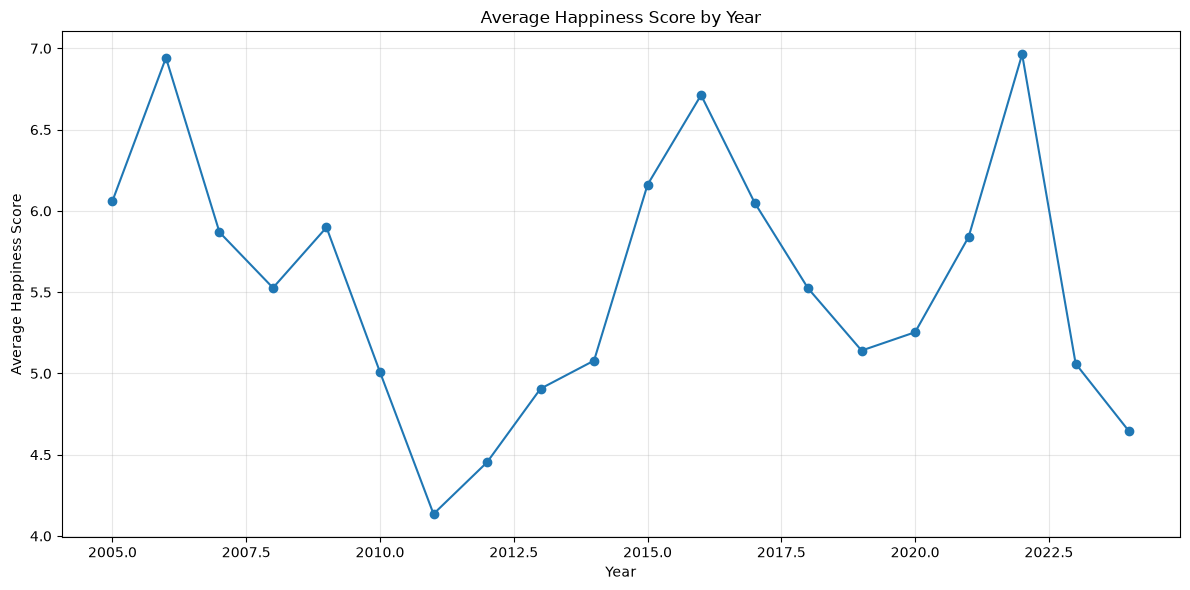

In [16]:
plt.figure(figsize=(12, 6))
plt.plot(yearly_happiness.index, yearly_happiness.values, marker='o')
plt.title('Average Happiness Score by Year')
plt.xlabel('Year')
plt.ylabel('Average Happiness Score')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [17]:
country_gdp = (
    df.groupby('Country')['GDP_per_Capita']
      .mean()
      .sort_values(ascending=False)
)
country_gdp


Country
UK              38642.557143
France          38123.249333
China           31338.395238
Canada          31102.242500
Australia       30597.156667
India           27974.927778
Germany         27864.484667
South Africa    27476.329375
Brazil          26529.812941
USA             24608.033077
Name: GDP_per_Capita, dtype: float64

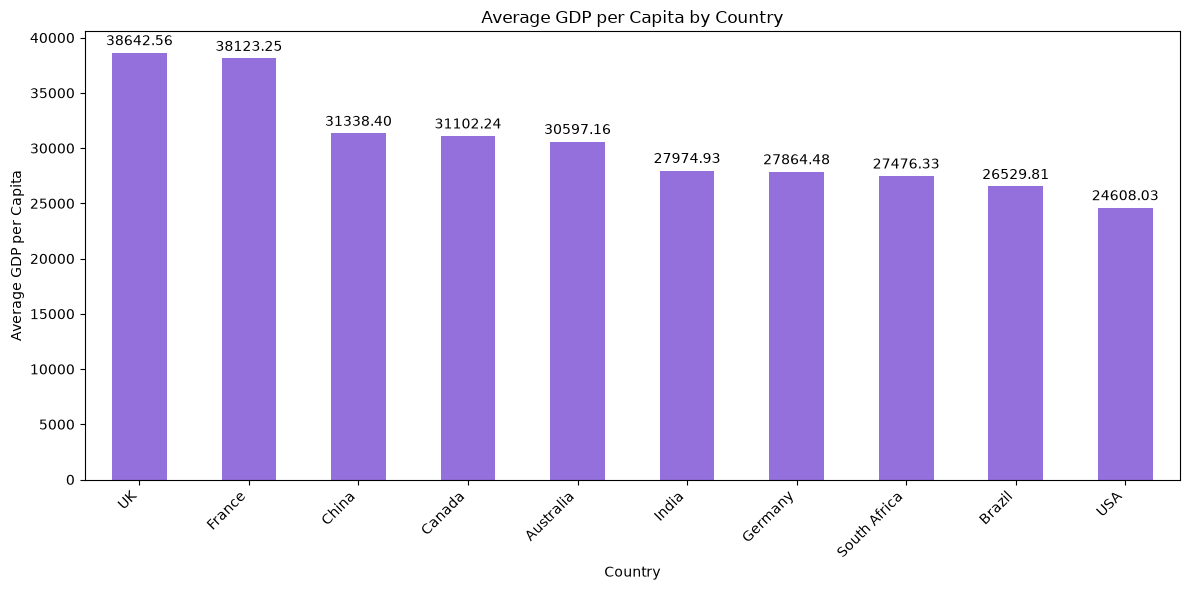

In [18]:
ax = country_gdp.plot(kind='bar', figsize=(12, 6), color='mediumpurple')
plt.bar_label(ax.containers[0], fmt='%.2f', padding=3)

plt.title('Average GDP per Capita by Country')
plt.xlabel('Country')
plt.ylabel('Average GDP per Capita')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


In [19]:
country_summary = df.groupby('Country').agg({
    'Year': 'count',
    'Happiness_Score': 'mean',
    'GDP_per_Capita': 'mean',
    'Social_Support': 'mean',
    'Healthy_Life_Expectancy': 'mean',
    'Freedom': 'mean',
    'Generosity': 'mean',
    'Corruption_Perception': 'mean'
}).rename(columns={'Year': 'Record_Count'})

country_summary


,Record_Count,Happiness_Score,GDP_per_Capita,Social_Support,Healthy_Life_Expectancy,Freedom,Generosity,Corruption_Perception
Country,,,,,,,,
Australia,18,6.024444,30597.156667,0.548889,69.881111,0.568889,0.185556,0.613333
Brazil,17,5.555294,26529.812941,0.415882,70.217059,0.458824,0.290000,0.494706
Canada,12,4.874167,31102.242500,0.562500,69.558333,0.686667,0.073333,0.336667
China,21,5.309524,31338.395238,0.355714,64.286190,0.579524,0.106190,0.393333
France,15,5.490667,38123.249333,0.570667,68.553333,0.576000,0.126667,0.484000
Germany,15,5.576667,27864.484667,0.546000,65.970667,0.444000,0.204000,0.580667
India,9,5.138889,27974.927778,0.567778,67.568889,0.591111,0.084444,0.666667
South Africa,16,5.585625,27476.329375,0.507500,69.362500,0.635000,0.153750,0.490000
UK,14,5.607857,38642.557143,0.576429,66.464286,0.422857,0.132857,0.453571


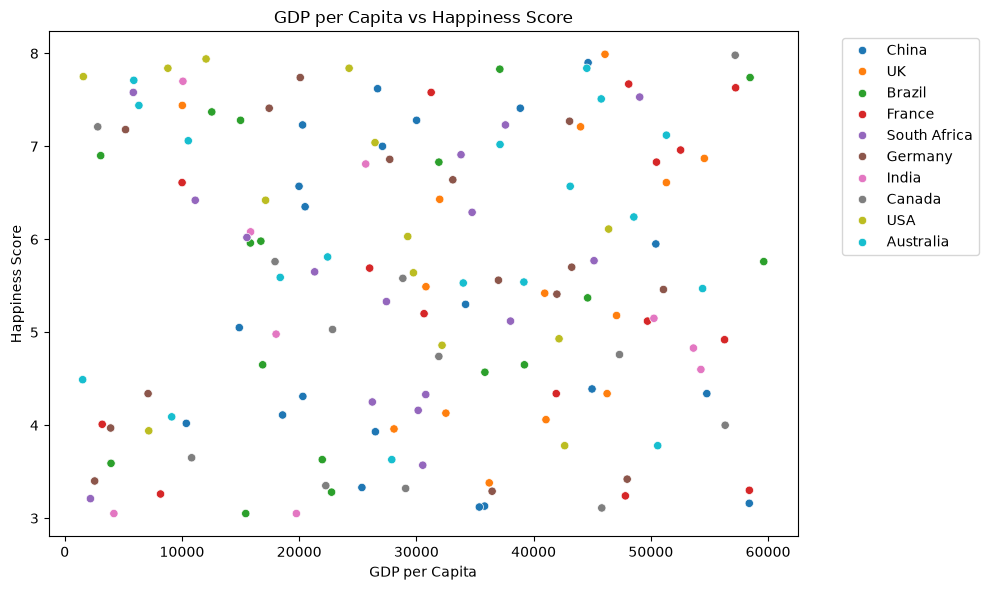

In [20]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='GDP_per_Capita',
    y='Happiness_Score',
    hue='Country'
)
plt.title('GDP per Capita vs Happiness Score')
plt.xlabel('GDP per Capita')
plt.ylabel('Happiness Score')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


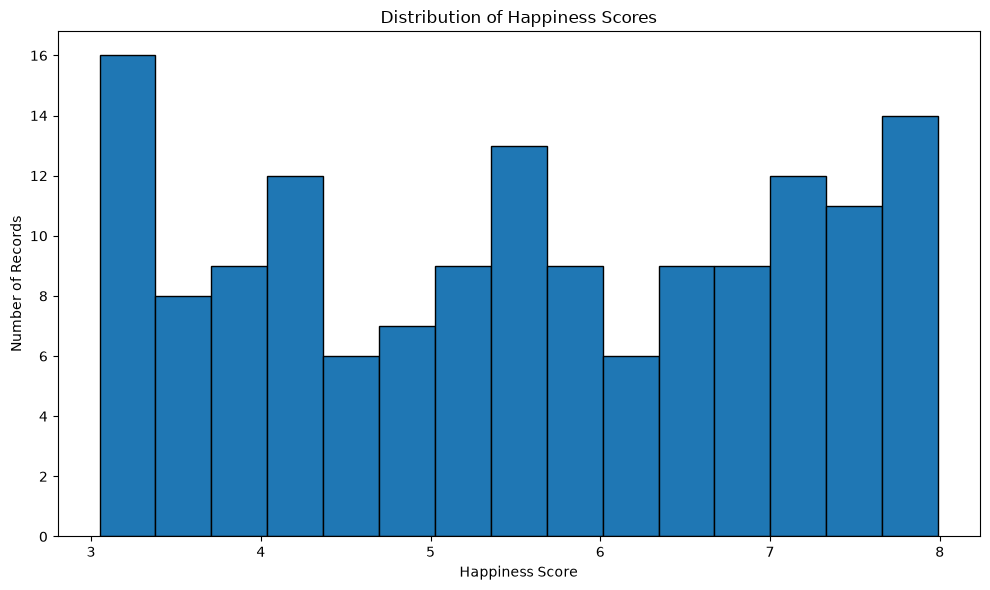

In [21]:
plt.figure(figsize=(10, 6))
plt.hist(df['Happiness_Score'], bins=15, edgecolor='black')
plt.title('Distribution of Happiness Scores')
plt.xlabel('Happiness Score')
plt.ylabel('Number of Records')
plt.tight_layout()
plt.show()


In [22]:
highest_country = top_countries.idxmax()
highest_score = top_countries.max()

print(f'Highest average happiness: {highest_country} ({highest_score:.2f})')


Highest average happiness: USA (6.16)
